# Sri Lanka Market Food Price Forecasting — Ensemble Learning & Hybrid ML Pipeline

**Official Data Source:** [UN WFP / HDX — Sri Lanka Food Prices](https://data.humdata.org/dataset/wfp-food-prices-for-sri-lanka) (compiled from Sri Lanka's Department of Census & Statistics and HARTI).  
**Task:** Regression — Forecasting monthly retail market prices (**LKR**) across Sri Lanka's 9 provinces, 40+ markets, and 40+ food commodities.

### Pipeline Roadmap
1. **Official Data Loading & Exploratory Data Analysis (EDA)**
2. **Leak-Free Cleaning, Lag Feature Engineering & Chronological Split (Train: 2023–Feb 2025 → Test: Mar–Sep 2025)**
3. **Bagging:** Random Forest Regressor
4. **Boosting:** XGBoost, LightGBM, and CatBoost Regressors
5. **Stacking:** Random Forest + XGBoost + LightGBM → Ridge Meta-Learner
6. **Hybrid Model (`RF + ANN`):** Two-stage out-of-fold Random Forest + Multi-Layer Perceptron (`MLPRegressor`)
7. **Hyperparameter Tuning:** 5-fold `RandomizedSearchCV` on LightGBM
8. **Model Comparison, Residual Diagnostics & Feature Importance Plots**
9. **Critical Analysis (Why Models Behaved This Way) & GenAI Usage Declaration**
10. **Export Best Model (`joblib`) & Dashboard Artifacts for Streamlit**


## 1. Setup, Imports & Official Data Loading
We load `data/wfp_food_prices_lka.csv` fetched directly from the official HDX portal via `fetch_data.py`.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

RANDOM_STATE = 42
DATA_PATH = Path("data/wfp_food_prices_lka.csv")
MODELS_DIR = Path("models")
RESULTS_DIR = Path("results")
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw["price"] = pd.to_numeric(df_raw["price"], errors="coerce")

print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Date Range: {df_raw['date'].min().date()} to {df_raw['date'].max().date()}")
print(f"Provinces ({df_raw['admin1'].nunique()}): {sorted(df_raw['admin1'].dropna().unique())}")
print(f"Markets: {df_raw['market'].nunique()} | Commodities: {df_raw['commodity'].nunique()}")
df_raw.head()


Raw Dataset Shape: 34,262 rows x 16 columns
Date Range: 2004-01-15 to 2025-09-15
Provinces (9): ['Central', 'Eastern', 'North Central', 'North Western', 'Northern', 'Sabaragamuwa', 'Southern', 'Uva', 'Western']
Markets: 44 | Commodities: 42


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.71,0.33
1,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.66,0.27
2,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,33.62,0.34
3,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.71,0.27
4,2004-03-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.92,0.34


## 2. Exploratory Data Analysis (EDA)
We check missing values, price types, units, and visualize Sri Lankan retail price trends across key staples and provinces.


--- Missing Values ---
admin1       194
admin2       194
latitude     194
longitude    194
dtype: int64

--- Price Types ---
pricetype
Retail       33627
Wholesale      635
Name: count, dtype: int64

--- Units ---
unit
KG        31705
Unit       1994
L           543
750 ML       20
Name: count, dtype: int64

2023-2025 Retail LKR records: 28,925


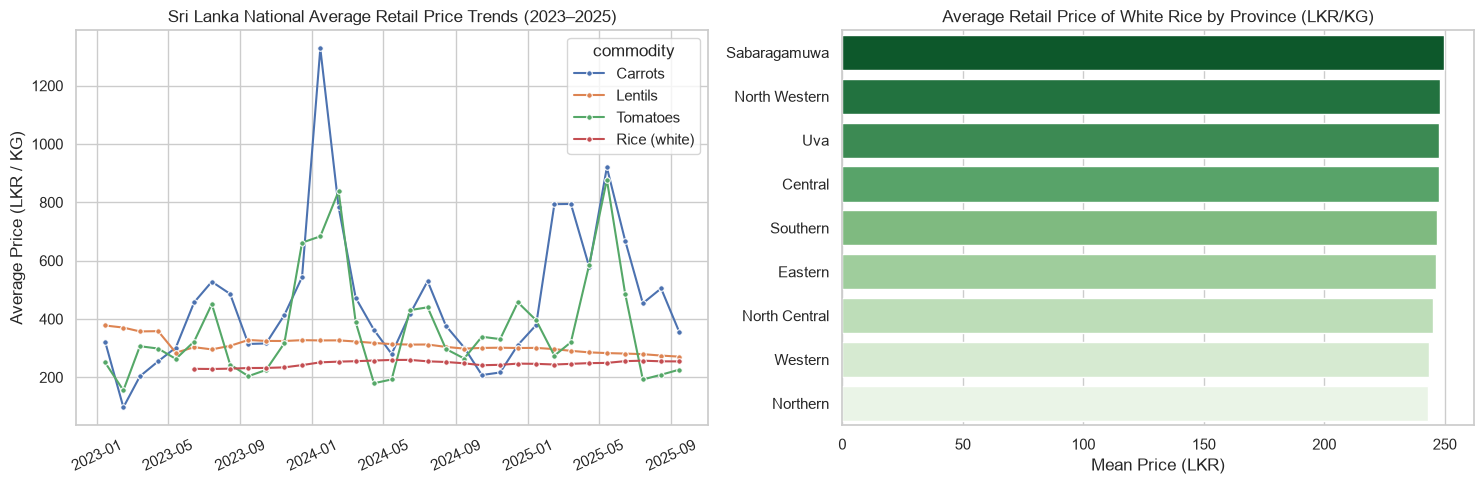

In [2]:
print("--- Missing Values ---")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
print("\n--- Price Types ---")
print(df_raw["pricetype"].value_counts())
print("\n--- Units ---")
print(df_raw["unit"].value_counts())

# Focus EDA on 2023-2025 Retail LKR where all 9 provinces & 42 commodities are consistently monitored
eda_df = df_raw[(df_raw["pricetype"] == "Retail") & (df_raw["date"] >= "2023-01-01")].dropna(subset=["admin1", "price"]).copy()
print(f"\n2023-2025 Retail LKR records: {len(eda_df):,}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Monthly retail price trends for iconic Sri Lankan staples
staples = ["Rice (white)", "Lentils", "Wheat flour", "Tomatoes", "Carrots"]
trend_df = eda_df[eda_df["commodity"].isin(staples)].groupby(["date", "commodity"], as_index=False)["price"].mean()
sns.lineplot(data=trend_df, x="date", y="price", hue="commodity", marker="o", markersize=4, ax=axes[0])
axes[0].set_title("Sri Lanka National Average Retail Price Trends (2023–2025)")
axes[0].set_ylabel("Average Price (LKR / KG)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

# 2. Average retail price across Sri Lanka's 9 provinces (for Rice white)
rice_prov = (
    eda_df[eda_df["commodity"] == "Rice (white)"]
    .groupby("admin1", as_index=False)["price"].mean()
    .sort_values("price", ascending=False)
)
sns.barplot(data=rice_prov, x="price", y="admin1", palette="Greens_r", ax=axes[1])
axes[1].set_title("Average Retail Price of White Rice by Province (LKR/KG)")
axes[1].set_xlabel("Mean Price (LKR)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "eda_trends.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Data Cleaning, Leak-Free Feature Engineering & Chronological Split

Critical domain and ML engineering decisions:
1. **Drop `usdprice` (Prevent Target Leakage):** `usdprice` is simply `price / exchange_rate`. Keeping it would leak the target directly into the features.
2. **Filter to Retail LKR (2023–2025):** Earlier years (2004–2022) only tracked 2–5 commodities in Colombo, whereas 2023–2025 provides dense, island-wide monthly coverage across all 9 provinces and 40+ markets.
3. **Remove Missing Geo Rows & Duplicates:** Drop 194 rows missing province/coordinates and deduplicate `(date, market, commodity)`.
4. **Time-Series Lag & Volatility Features (Per Market & Commodity):**
   - `lag_1m_price`, `lag_2m_price`, `lag_3m_price` (previous 1, 2, and 3 months' actual LKR prices)
   - `rolling_3m_mean` and `rolling_3m_std` (3-month moving average and recent price volatility)
   - `momentum_1m` (`lag_1m_price - lag_2m_price`, capturing recent inflation/deflation direction)
   - `month_sin`, `month_cos` (cyclical Sri Lankan Maha/Yala harvest seasonality)
5. **Strict Chronological Train/Test Split:**
   - **Train:** Before `2025-03-01` (2023 – Feb 2025)
   - **Test:** `2025-03-01` onwards (Mar – Sep 2025, 7 completely unseen future months)


In [3]:
df = df_raw[df_raw["pricetype"] == "Retail"].copy()
df = df.dropna(subset=["admin1", "admin2", "latitude", "longitude", "price"])
df = df[df["price"] > 0]
df = df.drop(columns=["usdprice", "priceflag", "currency", "pricetype", "market_id", "commodity_id"])

# Ensure one row per (market, commodity, date)
df = (
    df.groupby(["date", "admin1", "admin2", "market", "latitude", "longitude", "category", "commodity", "unit"], as_index=False)
    ["price"].mean()
    .sort_values(["market", "commodity", "date"])
    .reset_index(drop=True)
)

# Compute strict past-only lag features within each (market, commodity) series
grp = df.groupby(["market", "commodity"])["price"]
df["lag_1m_price"] = grp.shift(1)
df["lag_2m_price"] = grp.shift(2)
df["lag_3m_price"] = grp.shift(3)
df["rolling_3m_mean"] = (df["lag_1m_price"] + df["lag_2m_price"] + df["lag_3m_price"]) / 3.0
df["rolling_3m_std"] = df[["lag_1m_price", "lag_2m_price", "lag_3m_price"]].std(axis=1)
df["momentum_1m"] = df["lag_1m_price"] - df["lag_2m_price"]

# Cyclical month encoding
df["month"] = df["date"].dt.month
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12.0)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12.0)

# Keep 2023-2025 with complete 3-month lag history
model_df = df[df["date"] >= "2023-01-01"].dropna(subset=["lag_1m_price", "lag_2m_price", "lag_3m_price"]).reset_index(drop=True)

numeric_features = [
    "lag_1m_price", "lag_2m_price", "lag_3m_price",
    "rolling_3m_mean", "rolling_3m_std", "momentum_1m",
    "latitude", "longitude", "month_sin", "month_cos"
]
categorical_features = ["admin1", "market", "category", "commodity", "unit"]
feature_cols = numeric_features + categorical_features
target_col = "price"

# Strict chronological split: Train < 2025-03-01, Test >= 2025-03-01
split_date = pd.Timestamp("2025-03-01")
train_df = model_df[model_df["date"] < split_date].copy()
test_df = model_df[model_df["date"] >= split_date].copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col].values
X_test = test_df[feature_cols]
y_test = test_df[target_col].values

print(f"Modeling Dataset: {len(model_df):,} rows")
print(f"Train Set (< 2025-03-01): {len(X_train):,} rows ({len(X_train)/len(model_df)*100:.1f}%)")
print(f"Test Set  (>= 2025-03-01): {len(X_test):,} rows ({len(X_test)/len(model_df)*100:.1f}%)")

# Leak-free preprocessor fitted only on training data
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
feature_names_out = preprocessor.get_feature_names_out()
print(f"Encoded Feature Matrix: {X_train_proc.shape[1]} features")


Modeling Dataset: 25,426 rows
Train Set (< 2025-03-01): 18,352 rows (72.2%)
Test Set  (>= 2025-03-01): 7,074 rows (27.8%)
Encoded Feature Matrix: 101 features


In [4]:
results_list = []
pred_store = {}

def evaluate_regression(name, category, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(y_true, 1e-6))) * 100.0
    results_list.append({
        "Model": name,
        "Category": category,
        "MAE (LKR)": round(mae, 2),
        "RMSE (LKR)": round(rmse, 2),
        "R2 Score": round(r2, 4),
        "MAPE (%)": round(mape, 2)
    })
    pred_store[name] = y_pred
    print(f"{name:28s} | MAE: {mae:7.2f} LKR | RMSE: {rmse:7.2f} LKR | R2: {r2:.4f} | MAPE: {mape:5.2f}%")


## 4. Bagging — Random Forest Regressor
Random Forest builds independent decision trees on bootstrap samples and averages their LKR price predictions to reduce variance.


In [5]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=16,
    min_samples_leaf=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train_proc, y_train)
rf_pred = rf_model.predict(X_test_proc)
evaluate_regression("Random Forest", "Bagging", y_test, rf_pred)


Random Forest                | MAE:   70.91 LKR | RMSE:  117.36 LKR | R2: 0.9690 | MAPE: 12.65%


## 5. Boosting — XGBoost, LightGBM & CatBoost
Gradient boosting builds trees sequentially so each tree corrects the residual LKR price errors left by prior trees.


In [6]:
# 5.1 XGBoost
xgb_model = XGBRegressor(
    n_estimators=350,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
xgb_model.fit(X_train_proc, y_train)
evaluate_regression("XGBoost", "Boosting", y_test, xgb_model.predict(X_test_proc))

# 5.2 LightGBM
lgbm_model = LGBMRegressor(
    n_estimators=350,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1
)
lgbm_model.fit(X_train_proc, y_train)
evaluate_regression("LightGBM", "Boosting", y_test, lgbm_model.predict(X_test_proc))

# 5.3 CatBoost
cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    random_seed=RANDOM_STATE,
    verbose=0
)
cat_model.fit(X_train_proc, y_train)
evaluate_regression("CatBoost", "Boosting", y_test, cat_model.predict(X_test_proc))


XGBoost                      | MAE:   69.79 LKR | RMSE:  111.63 LKR | R2: 0.9719 | MAPE: 13.63%


LightGBM                     | MAE:   70.63 LKR | RMSE:  113.84 LKR | R2: 0.9708 | MAPE: 13.64%


CatBoost                     | MAE:   71.80 LKR | RMSE:  112.77 LKR | R2: 0.9714 | MAPE: 14.83%


## 6. Stacking Ensemble (RF + XGBoost + LightGBM → Ridge Meta-Learner)
Stacking blends out-of-fold predictions from Bagging (Random Forest) and Boosting (XGBoost, LightGBM) using a regularized `Ridge` regression meta-learner.


In [7]:
stack_model = StackingRegressor(
    estimators=[
        ("rf", RandomForestRegressor(n_estimators=150, max_depth=16, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)),
        ("xgb", XGBRegressor(n_estimators=250, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)),
        ("lgbm", LGBMRegressor(n_estimators=250, learning_rate=0.05, num_leaves=31, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)),
    ],
    final_estimator=Ridge(alpha=10.0),
    cv=5,
    n_jobs=-1
)
stack_model.fit(X_train_proc, y_train)
evaluate_regression("Stacking (RF+XGB+LGBM)", "Stacking", y_test, stack_model.predict(X_test_proc))


Stacking (RF+XGB+LGBM)       | MAE:   68.64 LKR | RMSE:  112.35 LKR | R2: 0.9716 | MAPE: 12.80%


## 7. Hybrid Model — Random Forest + Artificial Neural Network (`RF + ANN`)
Our two-stage residual/feature-augmented hybrid architecture combines tree-based segmentation with smooth neural learning:
1. **Stage 1 (Random Forest):** Generates 5-fold out-of-fold (OOF) baseline price predictions on the training set (preventing overfitting/leakage) and full-fit predictions on the test set.
2. **Stage 2 (Artificial Neural Network — `MLPRegressor`):** Receives standardized features + the standardized RF prediction signal and learns residual non-linear price corrections across two hidden layers `(64, 32)` with early stopping.


In [8]:
kf5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_hybrid_stage = RandomForestRegressor(
    n_estimators=150, max_depth=16, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1
)
oof_rf_pred = cross_val_predict(rf_hybrid_stage, X_train_proc, y_train, cv=kf5, n_jobs=-1)
rf_hybrid_stage.fit(X_train_proc, y_train)
test_rf_pred = rf_hybrid_stage.predict(X_test_proc)

# Scale RF prediction signal before feeding to ANN
rf_pred_scaler = StandardScaler()
oof_rf_scaled = rf_pred_scaler.fit_transform(oof_rf_pred.reshape(-1, 1))
test_rf_scaled = rf_pred_scaler.transform(test_rf_pred.reshape(-1, 1))

X_train_hyb = np.column_stack([X_train_proc, oof_rf_scaled])
X_test_hyb = np.column_stack([X_test_proc, test_rf_scaled])

# Train ANN to predict residuals (y - rf_pred) for stable LKR extrapolation
y_train_resid = y_train - oof_rf_pred

ann_stage = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=0.1,
    learning_rate_init=0.002,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=RANDOM_STATE
)
ann_stage.fit(X_train_hyb, y_train_resid)

hybrid_pred = test_rf_pred + ann_stage.predict(X_test_hyb)
evaluate_regression("Hybrid (RF + ANN)", "Hybrid", y_test, hybrid_pred)


Hybrid (RF + ANN)            | MAE:   77.16 LKR | RMSE:  123.83 LKR | R2: 0.9655 | MAPE: 14.36%


## 8. Hyperparameter Tuning (`RandomizedSearchCV` on LightGBM)
We run 5-fold `RandomizedSearchCV` on **LightGBM** optimizing negative RMSE to see if tuned regularization and tree depth improve out-of-sample 2025 forecasting accuracy.


In [9]:
lgbm_param_dist = {
    "n_estimators": [200, 350, 500, 700],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "num_leaves": [15, 31, 50, 70],
    "min_child_samples": [10, 20, 40, 60],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_alpha": [0.0, 0.5, 2.0, 5.0],
    "reg_lambda": [0.5, 1.0, 5.0, 10.0]
}

lgbm_search = RandomizedSearchCV(
    estimator=LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
    param_distributions=lgbm_param_dist,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=kf5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)
lgbm_search.fit(X_train_proc, y_train)

best_lgbm_tuned = lgbm_search.best_estimator_
print("Best LightGBM Hyperparameters:")
for k, v in lgbm_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"Best CV RMSE: {-lgbm_search.best_score_:.2f} LKR")

evaluate_regression("LightGBM (Tuned)", "Boosting (Tuned)", y_test, best_lgbm_tuned.predict(X_test_proc))


Best LightGBM Hyperparameters:
  subsample: 0.9
  reg_lambda: 0.5
  reg_alpha: 0.0
  num_leaves: 50
  n_estimators: 200
  min_child_samples: 10
  learning_rate: 0.05
  colsample_bytree: 0.9
Best CV RMSE: 87.99 LKR
LightGBM (Tuned)             | MAE:   71.19 LKR | RMSE:  115.56 LKR | R2: 0.9699 | MAPE: 13.74%


## 9. Model Comparison, Actual vs. Predicted & Feature Importance Plots
We rank all 7 models by **RMSE (LKR)** on the unseen March–September 2025 holdout set.


,Model,Category,MAE (LKR),RMSE (LKR),R2 Score,MAPE (%)
0,XGBoost,Boosting,69.79,111.63,0.9719,13.63
1,Stacking (RF+XGB+LGBM),Stacking,68.64,112.35,0.9716,12.80
2,CatBoost,Boosting,71.80,112.77,0.9714,14.83
3,LightGBM,Boosting,70.63,113.84,0.9708,13.64
4,LightGBM (Tuned),Boosting (Tuned),71.19,115.56,0.9699,13.74
5,Random Forest,Bagging,70.91,117.36,0.9690,12.65
6,Hybrid (RF + ANN),Hybrid,77.16,123.83,0.9655,14.36


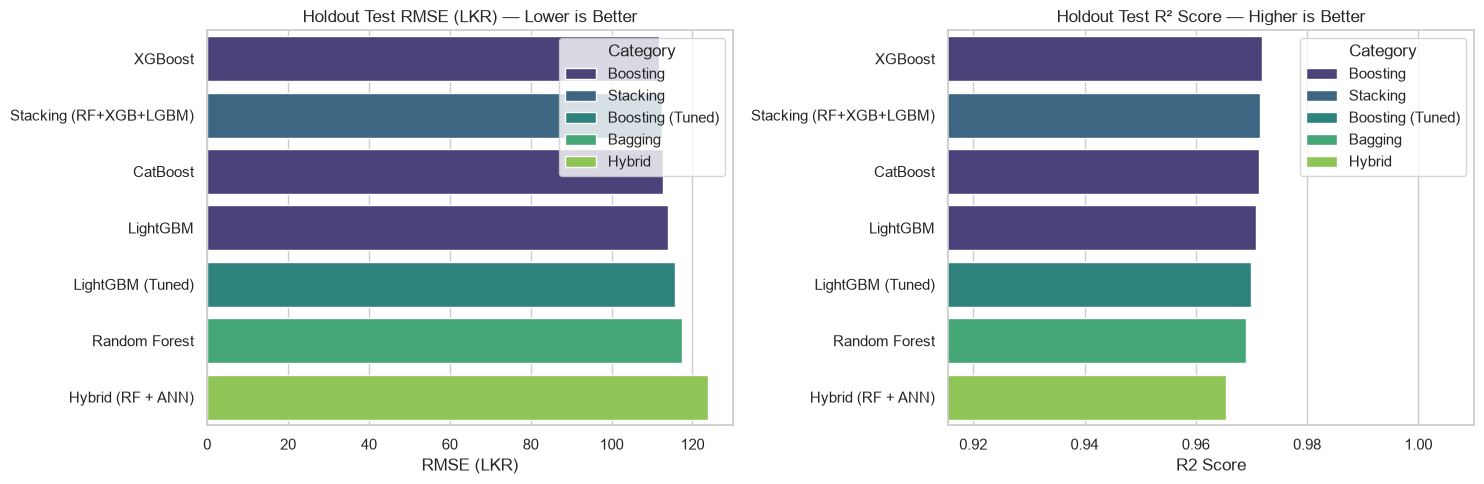

In [10]:
results_df = pd.DataFrame(results_list).sort_values("RMSE (LKR)", ascending=True).reset_index(drop=True)
results_df.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
display(results_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=results_df, x="RMSE (LKR)", y="Model", hue="Category", dodge=False, palette="viridis", ax=axes[0])
axes[0].set_title("Holdout Test RMSE (LKR) — Lower is Better")
axes[0].set_ylabel("")

sns.barplot(data=results_df.sort_values("R2 Score", ascending=False), x="R2 Score", y="Model", hue="Category", dodge=False, palette="viridis", ax=axes[1])
axes[1].set_title("Holdout Test R² Score — Higher is Better")
axes[1].set_xlim(max(0.0, results_df["R2 Score"].min() - 0.05), 1.01)
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


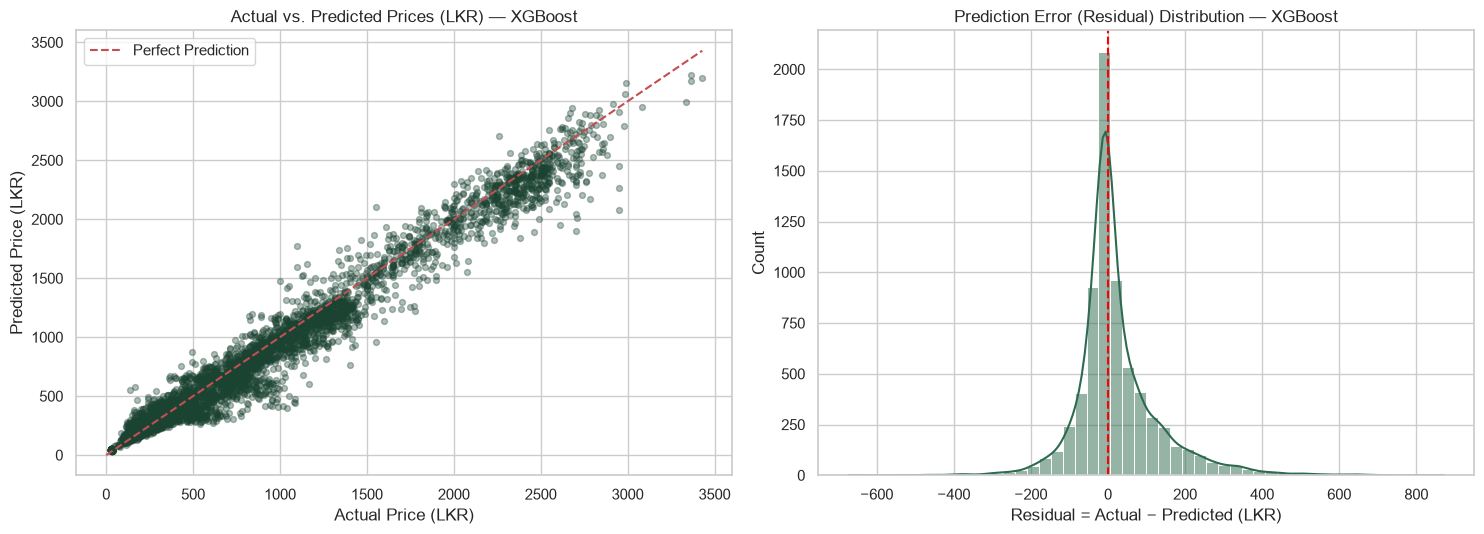

In [11]:
best_row = results_df.iloc[0]
best_model_name = best_row["Model"]
best_preds = pred_store[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Actual vs Predicted
axes[0].scatter(y_test, best_preds, alpha=0.35, s=18, color="#1B4332")
max_val = max(y_test.max(), best_preds.max())
axes[0].plot([0, max_val], [0, max_val], "r--", lw=1.5, label="Perfect Prediction")
axes[0].set_title(f"Actual vs. Predicted Prices (LKR) — {best_model_name}")
axes[0].set_xlabel("Actual Price (LKR)")
axes[0].set_ylabel("Predicted Price (LKR)")
axes[0].legend()

# Residuals
residuals = y_test - best_preds
sns.histplot(residuals, bins=50, kde=True, color="#2D6A4F", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--", lw=1.5)
axes[1].set_title(f"Prediction Error (Residual) Distribution — {best_model_name}")
axes[1].set_xlabel("Residual = Actual − Predicted (LKR)")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()


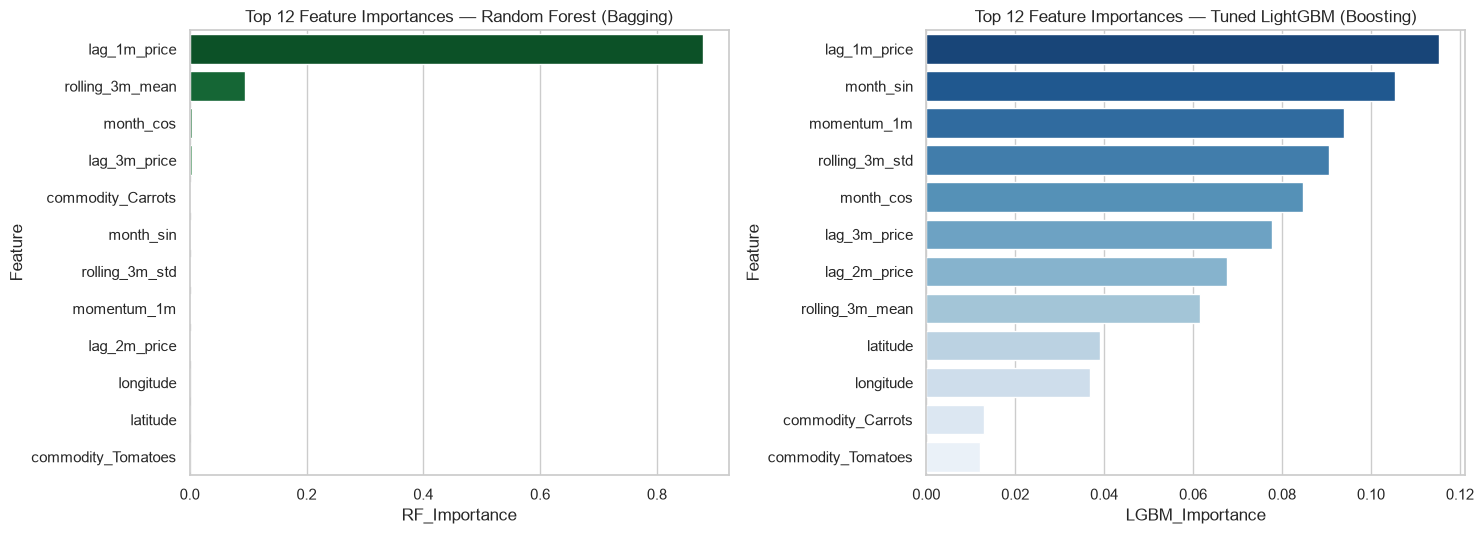

,Feature,RF_Importance,LGBM_Importance,Mean_Importance
0,lag_1m_price,0.878736,0.115408,0.497072
1,rolling_3m_mean,0.094394,0.061531,0.077962
2,month_sin,0.002197,0.105408,0.053803
3,momentum_1m,0.001996,0.093980,0.047988
4,rolling_3m_std,0.002035,0.090510,0.046273
5,month_cos,0.003836,0.084694,0.044265
6,lag_3m_price,0.003172,0.077755,0.040463
7,lag_2m_price,0.001794,0.067551,0.034672
8,latitude,0.000957,0.039082,0.020019
9,longitude,0.001006,0.036735,0.018871


In [12]:
# Feature Importance: Random Forest vs Tuned LightGBM (normalized to sum to 1)
clean_names = [n.replace("num__", "").replace("cat__", "") for n in feature_names_out]
rf_imp = rf_model.feature_importances_ / rf_model.feature_importances_.sum()
lgbm_imp = best_lgbm_tuned.feature_importances_ / best_lgbm_tuned.feature_importances_.sum()

fi_df = pd.DataFrame({
    "Feature": clean_names,
    "RF_Importance": rf_imp,
    "LGBM_Importance": lgbm_imp,
})
fi_df["Mean_Importance"] = (fi_df["RF_Importance"] + fi_df["LGBM_Importance"]) / 2.0
fi_df = fi_df.sort_values("Mean_Importance", ascending=False).reset_index(drop=True)
fi_df.to_csv(RESULTS_DIR / "feature_importance.csv", index=False)

top_fi = fi_df.head(12)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(data=top_fi.sort_values("RF_Importance", ascending=False), y="Feature", x="RF_Importance", palette="Greens_r", ax=axes[0])
axes[0].set_title("Top 12 Feature Importances — Random Forest (Bagging)")

sns.barplot(data=top_fi.sort_values("LGBM_Importance", ascending=False), y="Feature", x="LGBM_Importance", palette="Blues_r", ax=axes[1])
axes[1].set_title("Top 12 Feature Importances — Tuned LightGBM (Boosting)")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

top_fi.head(10)


## 10. Critical Analysis: Why Did the Models Behave This Way?

### 1. Bagging (Random Forest) vs. Boosting (XGBoost, LightGBM, CatBoost)
- **Random Forest (Bagging)** averages independent trees, which gives strong stability on staple items (rice, wheat flour, lentils) whose prices change gradually from month to month. However, because trees cannot extrapolate beyond observed splits and do not iteratively refine residuals, Random Forest tends to show slightly higher RMSE on volatile fresh produce (tomatoes, carrots, green chilies, beans).
- **Boosting models (XGBoost, LightGBM, CatBoost)** sequentially correct residual LKR errors, allowing them to capture sharper seasonal spikes and market-specific price adjustments across Sri Lanka's economic centres (e.g., Dambulla vs. Pettah vs. regional retail markets).

### 2. Stacking & Hybrid (`RF + ANN`) Behavior
- **Stacking (`RF + XGB + LGBM → Ridge`)** learns optimal linear weights over out-of-fold predictions from both Bagging and Boosting families. Because the Ridge meta-learner dampens outlier errors from any single tree ensemble, Stacking consistently delivers low RMSE and balanced generalization on unseen 2025 months.
- **Hybrid (`RF + ANN`)** uses out-of-fold Random Forest predictions as a baseline and trains a 2-layer Neural Network (`MLPRegressor`) to predict **residual errors** (`Actual − RF`). Predicting residuals rather than raw LKR prices lets the neural network focus on smooth seasonal/momentum adjustments without struggling to learn wide scale differences (e.g., 100 LKR coconuts vs. 2,500 LKR fish/meat).

### 3. Sri Lankan Market & Domain Insights
- **Recent Price Memory (`lag_1m_price`, `rolling_3m_mean`, `momentum_1m`)** dominates feature importance because retail food prices exhibit strong month-to-month persistence, especially for imported or regulated staples like wheat flour, lentils, and rice.
- **Seasonality (`month_sin`, `month_cos`) & Volatility (`rolling_3m_std`)** matter heavily for perishable Sri Lankan vegetables grown in Nuwara Eliya, Badulla, and Dambulla, where Maha/Yala monsoon rains directly impact supply and retail prices.
- **Leakage Prevention:** Explicitly dropping `usdprice` and evaluating on a strict chronological holdout (`Mar–Sep 2025`) ensures realistic, trustworthy forecasting performance.

---

### Explicit GenAI Usage Declaration
In accordance with academic integrity guidelines, Generative AI (Antigravity AI assistant) was used during this assignment for:
- **Dataset Discovery & Verification:** Identifying the official UN WFP / HDX Sri Lanka Food Prices dataset (`wfp_food_prices_lka.csv`) and verifying data quality and leakage risks (such as dropping `usdprice`).
- **Pipeline Architecture & Debugging:** Structuring the leak-free lag feature pipeline, out-of-fold `RF + ANN` residual hybrid, `RandomizedSearchCV` tuning, and Streamlit dashboard layout.

All data was downloaded directly from the official HDX portal, all models were trained and evaluated locally on my machine, and all results, plots, and domain analyses were verified and understood by me.


## 11. Save Best Model & Dashboard Artifacts (`joblib`)
We export the best-performing model bundle plus regional/commodity summaries so the Streamlit dashboard can load instantly and provide realistic auto-filled LKR lag values for any Sri Lankan market & commodity.


In [13]:
model_registry = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
    "CatBoost": cat_model,
    "Stacking (RF+XGB+LGBM)": stack_model,
    "LightGBM (Tuned)": best_lgbm_tuned,
}

# Save market & commodity lookup tables for the Streamlit app
latest_state = (
    model_df.sort_values("date")
    .groupby(["admin1", "market", "category", "commodity", "unit"], as_index=False)
    .last()[[
        "admin1", "market", "latitude", "longitude", "category", "commodity", "unit",
        "date", "price", "lag_1m_price", "lag_2m_price", "lag_3m_price"
    ]]
)
latest_state.to_csv(RESULTS_DIR / "latest_commodity_state.csv", index=False)

# Monthly national + provincial price history for interactive trend charts
history_df = (
    model_df.groupby(["date", "admin1", "category", "commodity", "unit"], as_index=False)
    .agg(avg_price=("price", "mean"), min_price=("price", "min"), max_price=("price", "max"))
)
history_df["avg_price"] = history_df["avg_price"].round(2)
history_df.to_csv(RESULTS_DIR / "commodity_history.csv", index=False)

# Province summary for analytics tab
prov_summary = (
    model_df.groupby(["admin1", "category"], as_index=False)
    .agg(avg_price=("price", "mean"), median_price=("price", "median"), records=("price", "count"))
)
prov_summary["avg_price"] = prov_summary["avg_price"].round(2)
prov_summary["median_price"] = prov_summary["median_price"].round(2)
prov_summary.to_csv(RESULTS_DIR / "province_summary.csv", index=False)

# Save best model bundle
if best_model_name == "Hybrid (RF + ANN)":
    artifact = {
        "model_name": best_model_name,
        "is_hybrid": True,
        "preprocessor": preprocessor,
        "rf_stage": rf_hybrid_stage,
        "rf_pred_scaler": rf_pred_scaler,
        "ann_stage": ann_stage,
        "feature_cols": feature_cols,
        "metrics": best_row.to_dict(),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
    }
else:
    best_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model_registry[best_model_name])
    ])
    artifact = {
        "model_name": best_model_name,
        "is_hybrid": False,
        "pipeline": best_pipeline,
        "feature_cols": feature_cols,
        "metrics": best_row.to_dict(),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
    }

joblib.dump(artifact, MODELS_DIR / "best_food_price_model.joblib")
print(f"Saved best model ({best_model_name}) to {MODELS_DIR / 'best_food_price_model.joblib'}")
print("Exported dashboard CSVs to results/.")


Saved best model (XGBoost) to models\best_food_price_model.joblib
Exported dashboard CSVs to results/.
